In [1]:
# ============================================================
# IMPORTING LIBRARIES
# ============================================================

# Data manipulation
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Google Drive
from google.colab import drive

# Train/test splitting
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Machine learning models
from sklearn.linear_model import LinearRegression, LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully")


Libraries imported successfully


In [2]:
# ============================================================
# MOUNTING GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ============================================================
# CHECKING GOOGLE DRIVE
# ============================================================

import os

# Show the contents of My Drive
drive_path = "/content/drive/MyDrive"

print("Files/folders in My Drive:")
#print(os.listdir(drive_path)[:50])
print("Just hidden from display")


Files/folders in My Drive:
Just hidden from display


In [4]:
print(os.listdir("/content/drive/MyDrive/ML_assignments_with_Abdul"))

['house_pricing_ml_exercise.csv', 'Week_2', 'Week_1', 'Week_3']


In [5]:
# ============================================================
# LOADING THE DATASET
# ============================================================

file_path = "/content/drive/MyDrive/ML_assignments_with_Abdul/house_pricing_ml_exercise.csv"

df_raw = pd.read_csv(file_path)

print("Dataset loaded successfully")
print("Shape:", df_raw.shape)

display(df_raw.head())

Dataset loaded successfully
Shape: (1208, 19)


,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
0,H0001,Frankfurt,Westend,Apartment,3,1,79.2,0,2004,Excellent,1,1.5,6.6,2.6,No,No,D,675000,1
1,H0002,Frankfurt,Gallus,Terraced House,5,2,127.3,514.9,1979,Average,2,4.1,7.4,3.6,No,Yes,D,716000,1
2,H0003,Frankfurt,Bockenheim,Apartment,2,1,45.8 sqm,0,2004,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,0
3,H0004,Hamburg,Harburg,Terraced House,5,2,182.5,529.9,2019,Needs Renovation,2,20.2,8.9,4.2,Yes,Yes,C,622000,1
4,H0005,Cologne,Sülz,Detached House,3,1,98.1,507.0,1979,Good,1,0.4,7.5,4.2,Yes,Yes,B,780000,1


In [6]:
# ============================================================
# INITIAL DATA INSPECTION
# ============================================================

print("First five rows:")
display(df_raw.head())

print("\nLast five rows:")
display(df_raw.tail())

print("\nDataset shape:")
print(df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

print("\nBasic statistical summary:")
display(df_raw.describe(include="all").T)

First five rows:


,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
0,H0001,Frankfurt,Westend,Apartment,3,1,79.2,0,2004,Excellent,1,1.5,6.6,2.6,No,No,D,675000,1
1,H0002,Frankfurt,Gallus,Terraced House,5,2,127.3,514.9,1979,Average,2,4.1,7.4,3.6,No,Yes,D,716000,1
2,H0003,Frankfurt,Bockenheim,Apartment,2,1,45.8 sqm,0,2004,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,0
3,H0004,Hamburg,Harburg,Terraced House,5,2,182.5,529.9,2019,Needs Renovation,2,20.2,8.9,4.2,Yes,Yes,C,622000,1
4,H0005,Cologne,Sülz,Detached House,3,1,98.1,507.0,1979,Good,1,0.4,7.5,4.2,Yes,Yes,B,780000,1



Last five rows:


,house_id,city,neighborhood,property_type,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,condition,parking_spaces,distance_city_center_km,school_rating_1_10,crime_rate_1_10,has_garden,has_balcony,energy_rating,sale_price_eur,high_price
1203,DUP0534,Cologne,Lindenthal,Apartment,3,1,84.2,0,1981,Good,1,5.1,6.4,5.1,Yes,Yes,E,541000,1
1204,DUP1080,Cologne,Nippe,Detached House,3,1,137.0,759.8,1972,Good,3,11.8,8.3,2.9,Yes,Yes,NaN,940000,1
1205,DUP0449,Frankfurt,Höchst,Apartment,2,2,90.1,0,2024,Average,0,5.6,7.2,3.3,No,No,D,378000,0
1206,DUP0440,Berlin,Neukölln,Terraced House,5,2,174.2,626.4,1991,Excellent,0,5.2,6.7,2.2,N,Yes,F,999000,1
1207,DUP0999,Leipzig,Plagwitz,Detached House,6,2,181.1,268.1,1970,Average,3,7.3,6.2,5.2,No,No,E,556000,1



Dataset shape:
(1208, 19)

Column names:
['house_id', 'city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony', 'energy_rating', 'sale_price_eur', 'high_price']

Data types:
house_id                   object
city                       object
neighborhood               object
property_type              object
bedrooms                   object
bathrooms                  object
living_area_sqm            object
lot_size_sqm               object
year_built                 object
condition                  object
parking_spaces              int64
distance_city_center_km    object
school_rating_1_10         object
crime_rate_1_10            object
has_garden                 object
has_balcony                object
energy_rating              object
sale_price_eur              int64
high_price                  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
house_id,1208,1208,DUP0999,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,1208,23,Hamburg,214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighborhood,1208,65,Kalk,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
property_type,1208,15,Apartment,549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,1191,8,3,318,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bathrooms,1190,7,1,691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
living_area_sqm,1181,847,65,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lot_size_sqm,1172,552,0,559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_built,1182,77,2004,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,1180,17,Good,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# ============================================================
# IDENTIFYING NUMERICAL AND CATEGORICAL VARIABLES
# ============================================================

print("Numerical columns according to pandas:")
print(df_raw.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical/object columns:")
print(df_raw.select_dtypes(exclude=np.number).columns.tolist())

Numerical columns according to pandas:
['parking_spaces', 'sale_price_eur', 'high_price']

Categorical/object columns:
['house_id', 'city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony', 'energy_rating']


In [8]:
# ============================================================
# CHECKING MISSING VALUES
# ============================================================

missing = df_raw.isnull().sum()

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df_raw) * 100).round(2)
})

display(missing_table.sort_values("Missing Values", ascending=False))

,Missing Values,Missing Percentage
lot_size_sqm,36,2.98
crime_rate_1_10,36,2.98
school_rating_1_10,32,2.65
distance_city_center_km,28,2.32
condition,28,2.32
living_area_sqm,27,2.24
year_built,26,2.15
energy_rating,25,2.07
bathrooms,18,1.49
bedrooms,17,1.41


In [9]:
# ============================================================
# CHECKING DUPLICATES
# ============================================================

# Exact duplicate rows
exact_duplicates = df_raw.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

# Checking duplicates while ignoring "house_id"

property_columns = [
    c for c in df_raw.columns
    if c != "house_id"
]

property_duplicates = df_raw.duplicated(
    subset=property_columns
).sum()

print(
    "Duplicate property records when house_id is ignored:",
    property_duplicates
)

Exact duplicate rows: 0
Duplicate property records when house_id is ignored: 8


In [10]:
# ============================================================
# INSPECTING CATEGORICAL VALUES
# ============================================================

categorical_columns = [
    "city",
    "neighborhood",
    "property_type",
    "condition",
    "has_garden",
    "has_balcony",
    "energy_rating"
]

for column in categorical_columns:
    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)
    print(df_raw[column].value_counts(dropna=False))


city
city
Hamburg       214
Berlin        205
Frankfurt     197
Cologne       189
Munich        189
Leipzig       170
frankfurt       5
leipzig         4
Berln           4
HAMBURG         4
Hambug          3
BERLIN          3
LEIPZIG         3
Frankfurt       3
Colgne          2
Koeln           2
Frankfrut       2
Münich          2
munich          2
Leipzg          2
cologne         1
berlin          1
hamburg         1
Name: count, dtype: int64

neighborhood
neighborhood
Kalk               43
Charlottenburg     42
Neukölln           41
Sachsenhausen      40
Winterhude         40
Harburg            39
Connewitz          38
Altona             38
Bockenheim         38
Pankow             37
Grünau             36
Porz               36
Wandsbek           36
Maxvorstadt        35
Pasing             35
Eppendorf          34
Höchst             34
Giesing            32
Westend            31
Eimsbüttel         30
Spandau            30
Plagwitz           29
Lindenthal         29
Sendling        

In [11]:
# ============================================================
# CREATING A CLEANING COPY
# ============================================================

df = df_raw.copy()

# Treating question marks as missing values
df = df.replace("?", np.nan)

print("Cleaning copy created")

Cleaning copy created


In [12]:
# ============================================================
# CLEANING NUMERICAL COLUMNS
# ============================================================

numeric_columns_to_clean = [
    "bedrooms",
    "bathrooms",
    "living_area_sqm",
    "lot_size_sqm",
    "year_built",
    "distance_city_center_km",
    "school_rating_1_10",
    "crime_rate_1_10"
]

for column in numeric_columns_to_clean:

    # Converting values to strings temporarily so that
    # we can remove unwanted text
    series = df[column].astype(str).str.strip()

    # Converting the string "NaN" back to a real missing value
    series = series.replace("nan", np.nan)

    # Example:
    # "1 baths" -> "1"
    if column == "bathrooms":
        series = series.str.replace(
            r"\s*baths?\s*$",
            "",
            regex=True
        )

    # Example:
    # "90m2" -> "90"
    # "90 sqm" -> "90"
    if column in ["living_area_sqm", "lot_size_sqm"]:
        series = series.str.replace(
            r"\s*(sqm|m2)\s*$",
            "",
            regex=True
        )

    # Converting everything possible to numbers
    # (Invalid values become NaN.)
    df[column] = pd.to_numeric(
        series,
        errors="coerce"
    )

print("Numerical cleaning complete")

display(df[numeric_columns_to_clean].head())

Numerical cleaning complete


,bedrooms,bathrooms,living_area_sqm,lot_size_sqm,year_built,distance_city_center_km,school_rating_1_10,crime_rate_1_10
0,3.0,1.0,79.2,0.0,2004.0,1.5,6.6,2.6
1,5.0,2.0,127.3,514.9,1979.0,4.1,7.4,3.6
2,2.0,1.0,45.8,0.0,2004.0,4.2,8.7,4.3
3,5.0,2.0,182.5,529.9,2019.0,20.2,8.9,4.2
4,3.0,1.0,98.1,507.0,1979.0,0.4,7.5,4.2


In [13]:
# ============================================================
# NORMALISING CATEGORICAL TEXT
# ============================================================

categorical_columns = [
    "city",
    "neighborhood",
    "property_type",
    "condition",
    "has_garden",
    "has_balcony",
    "energy_rating"
]

for column in categorical_columns:

    # String conversion
    df[column] = df[column].astype(str)

    # Removing leading/trailing whitespace
    df[column] = df[column].str.strip()

    # Converting to lowercase
    df[column] = df[column].str.lower()

    # Converting the string "NaN" back to missing
    df[column] = df[column].replace("nan", np.nan)

print("Categorical text normalised")

Categorical text normalised


In [14]:
# ============================================================
# FIXING INCONSISTENT CATEGORIES
# ============================================================

# ------------------------------------------------------------
# CITY
# ------------------------------------------------------------

city_mapping = {
    "frankfrut": "frankfurt",
    "hambug": "hamburg",
    "berln": "berlin",
    "colgne": "cologne",
    "koeln": "cologne",
    "münich": "munich",
    "leipzg": "leipzig"
}

df["city"] = df["city"].replace(city_mapping)


# ------------------------------------------------------------
# PROPERTY TYPE
# ------------------------------------------------------------

property_type_mapping = {
    "apartmnt": "apartment",
    "detatched house": "detached house",
    "detached": "detached house",
    "terraced hse": "terraced house",
    "terrace house": "terraced house",
    "semi detached": "semi-detached",
    "semi-detatched": "semi-detached"
}

df["property_type"] = df["property_type"].replace(
    property_type_mapping
)


# ------------------------------------------------------------
# CONDITION
# ------------------------------------------------------------

condition_mapping = {
    "gud": "good",
    "averge": "average",
    "excelent": "excellent",
    "needs renovaton": "needs renovation",
    "renovation needed": "needs renovation"
}

df["condition"] = df["condition"].replace(
    condition_mapping
)


# ------------------------------------------------------------
# ENERGY RATING
# ------------------------------------------------------------

energy_mapping = {
    "dd": "d"
}

df["energy_rating"] = df["energy_rating"].replace(
    energy_mapping
)


# ------------------------------------------------------------
# NEIGHBORHOOD
# ------------------------------------------------------------

neighborhood_mapping = {
    "bockenhei": "bockenheim",
    "bogenhause": "bogenhausen",
    "charlottenbur": "charlottenburg",
    "connewit": "connewitz",
    "ehrenfel": "ehrenfeld",
    "gallu": "gallus",
    "giesin": "giesing",
    "gohli": "gohlis",
    "grüna": "grünau",
    "harbur": "harburg",
    "kreuzber": "kreuzberg",
    "nippe": "nippes",
    "norden": "nordend",
    "panko": "pankow",
    "wandsbe": "wandsbek"
}

df["neighborhood"] = df["neighborhood"].replace(
    neighborhood_mapping
)

# Capitalising names of cities and neighbourhoods for final output
df["city"] = df["city"].str.title()
df["neighborhood"] = df["neighborhood"].str.title()

print("Categorical inconsistencies corrected")
print("City and neighborhood names formatted for final output")

print("\nCities after cleaning:")
print(sorted(df["city"].dropna().unique()))

Categorical inconsistencies corrected
City and neighborhood names formatted for final output

Cities after cleaning:
['Berlin', 'Cologne', 'Frankfurt', 'Hamburg', 'Leipzig', 'Munich']


In [15]:
# ============================================================
# CONVERTING BOOLEAN COLUMNS
# ============================================================

boolean_mapping = {
    "yes": 1,
    "y": 1,
    "true": 1,
    "1": 1,

    "no": 0,
    "n": 0,
    "false": 0,
    "0": 0
}

for column in ["has_garden", "has_balcony"]:

    df[column] = df[column].map(boolean_mapping)

print("Boolean columns converted to 0/1")

display(df[["has_garden", "has_balcony"]].head())

Boolean columns converted to 0/1


,has_garden,has_balcony
0,0,0
1,0,1
2,0,1
3,1,1
4,1,1


In [16]:
# ============================================================
# CHECKING CLEANED DATA
# ============================================================

print("Data types after cleaning:")
print(df.dtypes)

print("\nMissing values after cleaning:")
display(
    pd.DataFrame({
        "Missing": df.isnull().sum(),
        "Percentage": (
            df.isnull().sum() / len(df) * 100
        ).round(2)
    }).sort_values(
        "Missing",
        ascending=False
    )
)

Data types after cleaning:
house_id                    object
city                        object
neighborhood                object
property_type               object
bedrooms                   float64
bathrooms                  float64
living_area_sqm            float64
lot_size_sqm               float64
year_built                 float64
condition                   object
parking_spaces               int64
distance_city_center_km    float64
school_rating_1_10         float64
crime_rate_1_10            float64
has_garden                   int64
has_balcony                  int64
energy_rating               object
sale_price_eur               int64
high_price                   int64
dtype: object

Missing values after cleaning:


,Missing,Percentage
lot_size_sqm,47,3.89
crime_rate_1_10,41,3.39
year_built,37,3.06
distance_city_center_km,37,3.06
living_area_sqm,37,3.06
school_rating_1_10,36,2.98
energy_rating,35,2.90
condition,31,2.57
bathrooms,22,1.82
bedrooms,22,1.82


In [17]:
# ============================================================
# REMOVING DUPLICATE PROPERTY RECORDS
# ============================================================

before_duplicates = len(df)

# house_id is deliberately excluded because two records
# can represent the same property while having different IDs.
duplicate_check_columns = [
    c for c in df.columns
    if c != "house_id"
]

df = df.drop_duplicates(
    subset=duplicate_check_columns,
    keep="first"
).copy()

after_duplicates = len(df)

print("Rows before duplicate removal:", before_duplicates)
print("Rows after duplicate removal:", after_duplicates)
print("Rows removed:", before_duplicates - after_duplicates)

Rows before duplicate removal: 1208
Rows after duplicate removal: 1200
Rows removed: 8


In [18]:
# ============================================================
# VERIFYING HIGH_PRICE TARGET
# ============================================================

# Creating "high_price" using the assignment definition
df["high_price_created"] = (
    df["sale_price_eur"] >= 500000
).astype(int)

# Comparing it to the supplied high_price column
mismatches = (
    df["high_price"] != df["high_price_created"]
).sum()

print("Number of high_price mismatches:", mismatches)

if mismatches == 0:
    print(
        "The supplied high_price column exactly matches "
        "the assignment definition."
    )
else:
    print(
        "There are mismatches. They should be investigated "
        "before continuing."
    )

Number of high_price mismatches: 0
The supplied high_price column exactly matches the assignment definition.


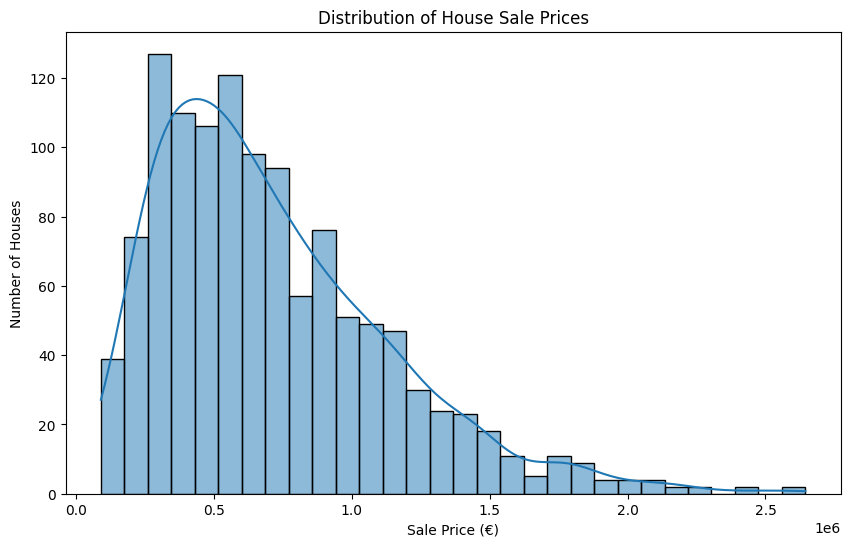

In [19]:
# ============================================================
# SALE PRICE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

sns.histplot(
    df["sale_price_eur"],
    bins=30,
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price (€)")
plt.ylabel("Number of Houses")

plt.show()

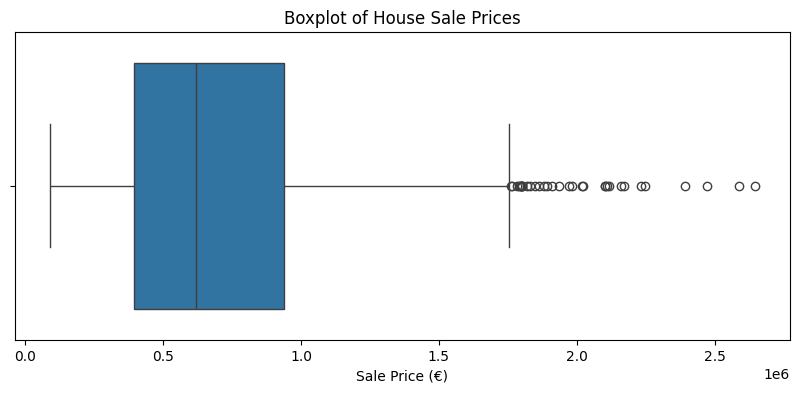

In [20]:
# ============================================================
# SALE PRICE BOXPLOT
# ============================================================

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["sale_price_eur"]
)

plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price (€)")

plt.show()

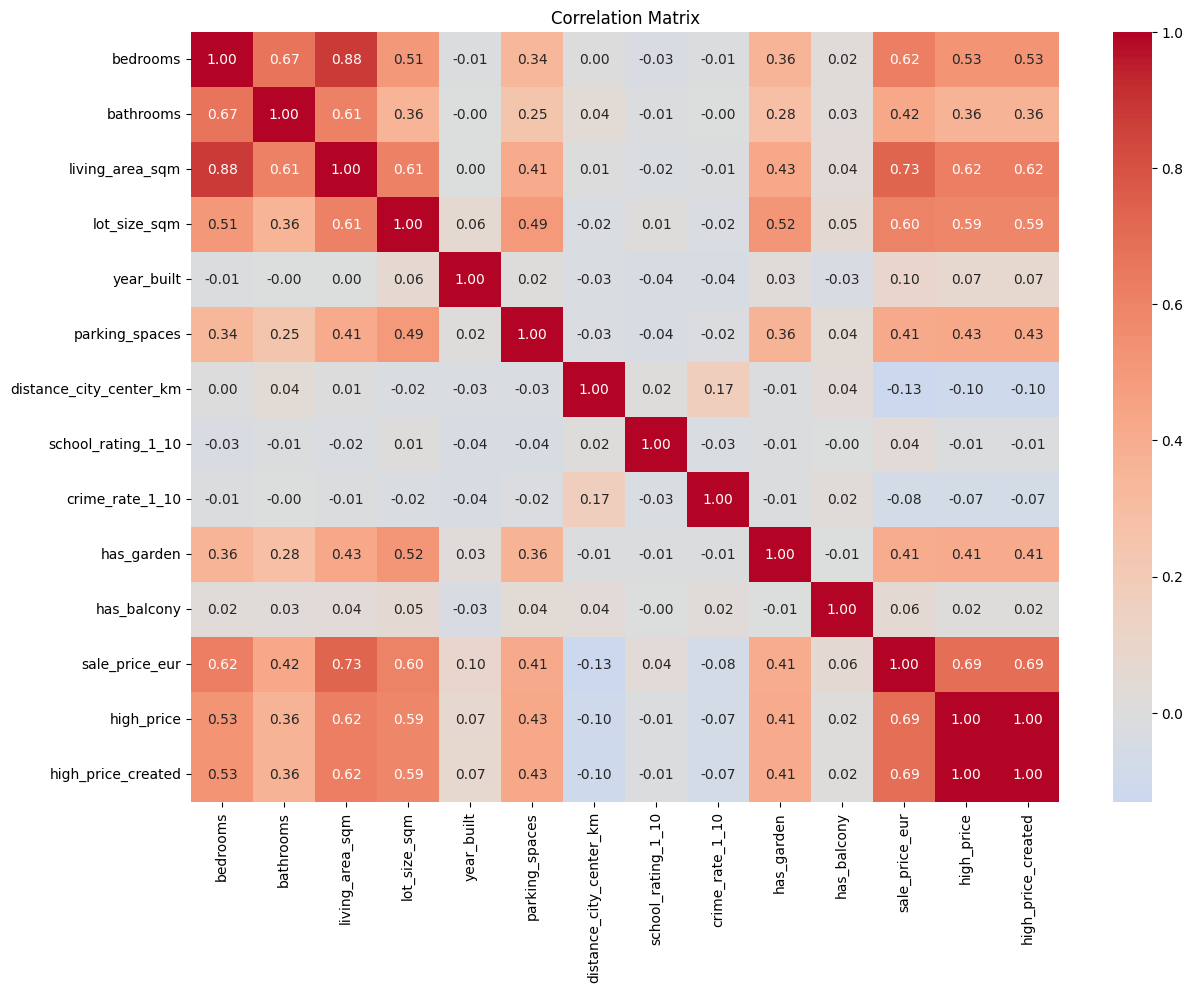

In [21]:
# ============================================================
# CORRELATION HEATMAP
# ============================================================

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.show()

In [22]:
# ============================================================
# CORRELATION WITH SALE PRICE
# ============================================================

price_correlations = (
    numeric_df.corr()["sale_price_eur"]
    .sort_values(ascending=False)
)

display(
    price_correlations.to_frame(
        name="Correlation with Sale Price"
    )
)

,Correlation with Sale Price
sale_price_eur,1.000000
living_area_sqm,0.730288
high_price,0.690298
high_price_created,0.690298
bedrooms,0.618132
lot_size_sqm,0.603619
bathrooms,0.422132
parking_spaces,0.414790
has_garden,0.407758
year_built,0.098827


,sale_price_eur
city,
Munich,1040000.0
Hamburg,653500.0
Frankfurt,600500.0
Berlin,574000.0
Cologne,569000.0
Leipzig,370000.0


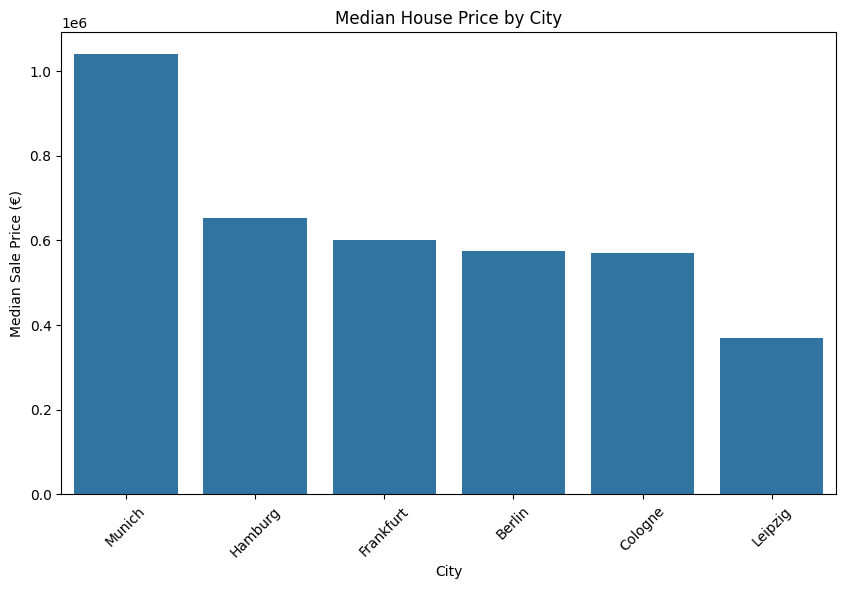

In [23]:
# ============================================================
# PRICE BY CITY
# ============================================================

city_prices = (
    df.groupby("city")["sale_price_eur"]
    .median()
    .sort_values(ascending=False)
)

display(city_prices)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=city_prices.index,
    y=city_prices.values
)

plt.title("Median House Price by City")
plt.xlabel("City")
plt.ylabel("Median Sale Price (€)")

plt.xticks(rotation=45)

plt.show()

,sale_price_eur
property_type,
semi-detached,948000.0
detached house,935000.0
terraced house,878500.0
apartment,393000.0


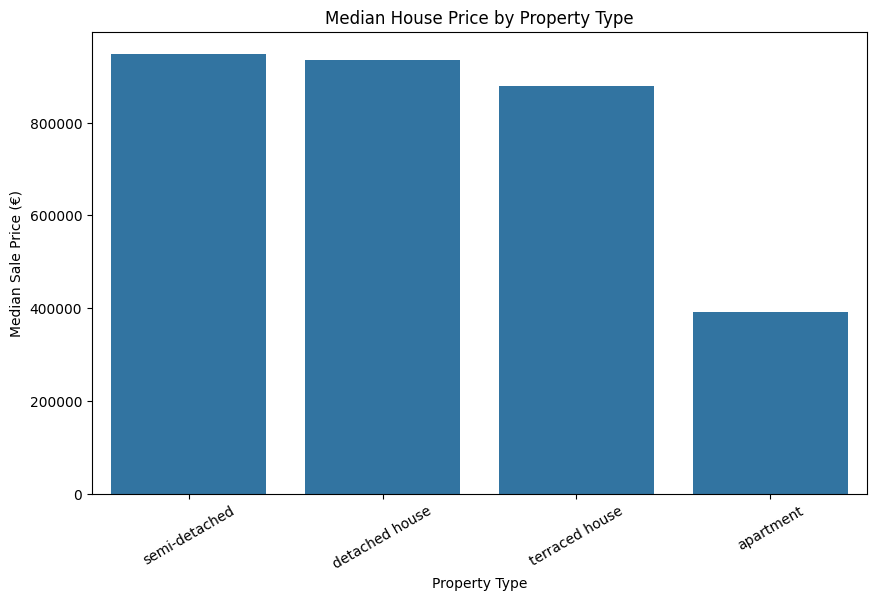

In [24]:
# ============================================================
# PRICE BY PROPERTY TYPE
# ============================================================

property_prices = (
    df.groupby("property_type")["sale_price_eur"]
    .median()
    .sort_values(ascending=False)
)

display(property_prices)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=property_prices.index,
    y=property_prices.values
)

plt.title("Median House Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Median Sale Price (€)")

plt.xticks(rotation=30)

plt.show()

,sale_price_eur
condition,
average,648000.0
good,623500.0
excellent,610000.0
needs renovation,569000.0


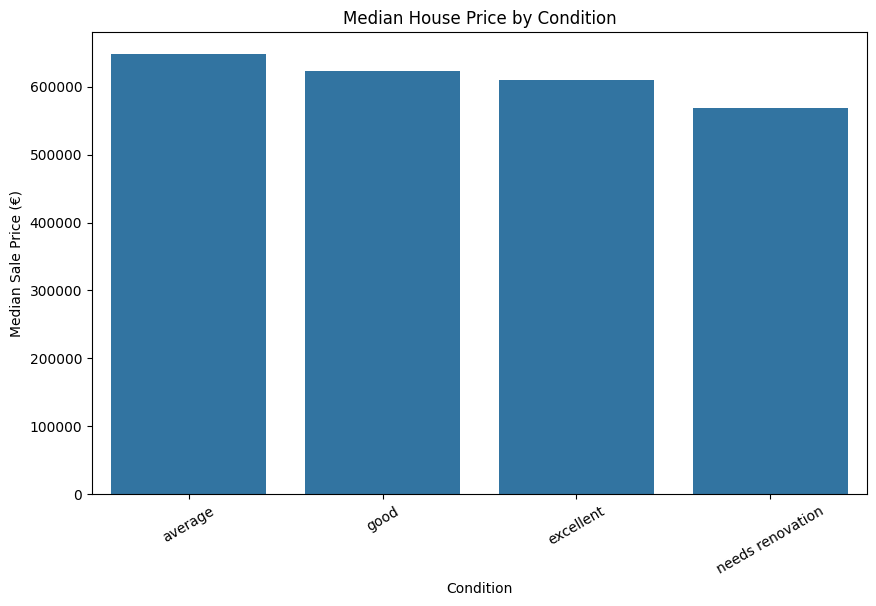

In [25]:
# ============================================================
# PRICE BY CONDITION
# ============================================================

condition_prices = (
    df.groupby("condition")["sale_price_eur"]
    .median()
    .sort_values(ascending=False)
)

display(condition_prices)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=condition_prices.index,
    y=condition_prices.values
)

plt.title("Median House Price by Condition")
plt.xlabel("Condition")
plt.ylabel("Median Sale Price (€)")

plt.xticks(rotation=30)

plt.show()

In [26]:
# ============================================================
# PART A - LINEAR REGRESSION
# DEFINING FEATURES AND TARGET
# ============================================================

# Target: sale_price_eur

y_linear = df["sale_price_eur"]

# We do not use the following as predictors:
# - house_id: just an identifier
# - sale_price_eur: target itself
# - high_price: derived from sale_price, so using it would be leakage
# - high_price_created: also derived from sale_price

X_linear = df.drop(
    columns=[
        "house_id",
        "sale_price_eur",
        "high_price",
        "high_price_created"
    ]
)

print("Features used for linear regression:")
print(X_linear.columns.tolist())

print("\nTarget:")
print("sale_price_eur")

Features used for linear regression:
['city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony', 'energy_rating']

Target:
sale_price_eur


In [27]:
# ============================================================
# IDENTIFYING FEATURE TYPES
# ============================================================

linear_numeric_features = (
    X_linear
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

linear_categorical_features = (
    X_linear
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print("Numerical features:")
print(linear_numeric_features)

print("\nCategorical features:")
print(linear_categorical_features)

Numerical features:
['bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony']

Categorical features:
['city', 'neighborhood', 'property_type', 'condition', 'energy_rating']


In [28]:
# ============================================================
# TRAIN/TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_linear,
    y_linear,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 960
Testing observations: 240


In [29]:
# ============================================================
# LINEAR REGRESSION PREPROCESSING
# ============================================================

# Numerical preprocessing:
# Missing numerical values are replaced with the median.
numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Categorical preprocessing:
# 1. Missing categories -> most-frequent category
# 2. Categories -> one-hot encoded numerical columns
categorical_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

# Combining both preprocessing strategies
preprocessor_linear = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_preprocessor,
            linear_numeric_features
        ),
        (
            "categorical",
            categorical_preprocessor,
            linear_categorical_features
        )
    ]
)

print("Linear Regression preprocessing pipeline created")

Linear Regression preprocessing pipeline created


In [30]:
# ============================================================
# TRAINING LINEAR REGRESSION
# ============================================================

linear_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor_linear
        ),
        (
            "model",
            LinearRegression()
        )
    ]
)

# Training the complete pipeline
linear_model.fit(
    X_train,
    y_train
)

print("Linear regression model trained successfully")

Linear regression model trained successfully


In [31]:
# ============================================================
# LINEAR REGRESSION PREDICTIONS
# ============================================================

linear_predictions = linear_model.predict(X_test)

print("First 10 predictions:")
print(linear_predictions[:10])

First 10 predictions:
[ 900778.2986718   950648.19660593  706272.721496   1090339.00256304
  884943.60605054 1570572.08686673  321503.05156159  701400.08959585
  614740.58763201 1329799.69756126]


In [32]:
# ============================================================
# EVALUATING LINEAR REGRESSION
# ============================================================

mae = mean_absolute_error(
    y_test,
    linear_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression Results")
print("=" * 40)

print(f"MAE  : €{mae:,.2f}")
print(f"RMSE : €{rmse:,.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Results
MAE  : €100,874.23
RMSE : €140,585.37
R²   : 0.8796


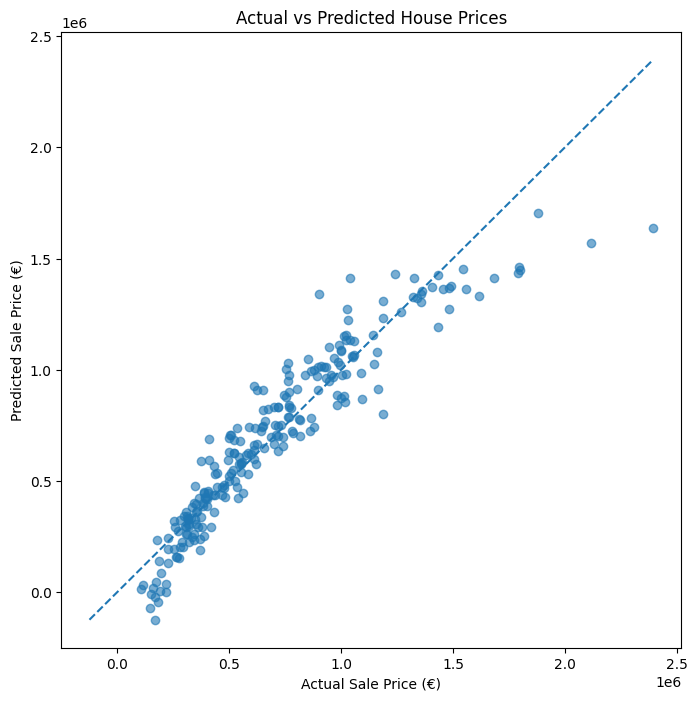

In [33]:
# ============================================================
# ACTUAL VS PREDICTED PRICES
# ============================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.6
)

# Perfect prediction line
minimum = min(
    y_test.min(),
    linear_predictions.min()
)

maximum = max(
    y_test.max(),
    linear_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Sale Price (€)")
plt.ylabel("Predicted Sale Price (€)")

plt.show()

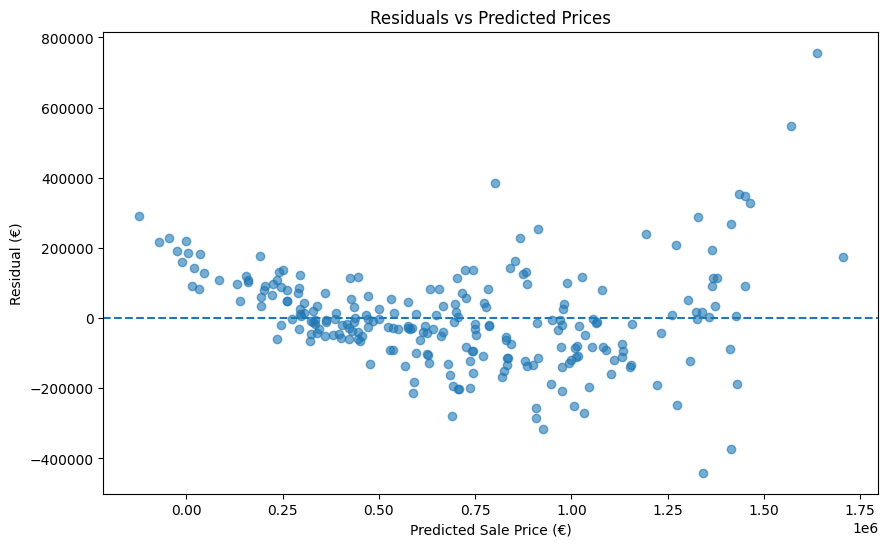

In [34]:
# ============================================================
# RESIDUAL ANALYSIS
# ============================================================

residuals = y_test - linear_predictions

plt.figure(figsize=(10, 6))

plt.scatter(
    linear_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Residuals vs Predicted Prices")
plt.xlabel("Predicted Sale Price (€)")
plt.ylabel("Residual (€)")

plt.show()

In [35]:
# ============================================================
# LINEAR REGRESSION COEFFICIENTS
# ============================================================

# Getting the fitted preprocessing object
fitted_preprocessor = (
    linear_model
    .named_steps["preprocessing"]
)

# Getting the transformed feature names
feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

# Obtaining model coefficients
coefficients = (
    linear_model
    .named_steps["model"]
    .coef_
)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Absolute Coefficient (useful for ranking)
coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coefficient_table.head(20))

,Feature,Coefficient,Absolute_Coefficient
15,categorical__city_Munich,305915.246360,305915.246360
27,categorical__neighborhood_Harburg,-250826.009012,250826.009012
17,categorical__neighborhood_Bogenhausen,230876.120957,230876.120957
42,categorical__neighborhood_Schwabing,220867.264879,220867.264879
48,categorical__neighborhood_Westend,202280.729392,202280.729392
32,categorical__neighborhood_Maxvorstadt,199890.294295,199890.294295
14,categorical__city_Leipzig,-192290.489807,192290.489807
40,categorical__neighborhood_Porz,-184248.310245,184248.310245
47,categorical__neighborhood_Wandsbek,-183587.386513,183587.386513
44,categorical__neighborhood_Spandau,-177066.667410,177066.667410


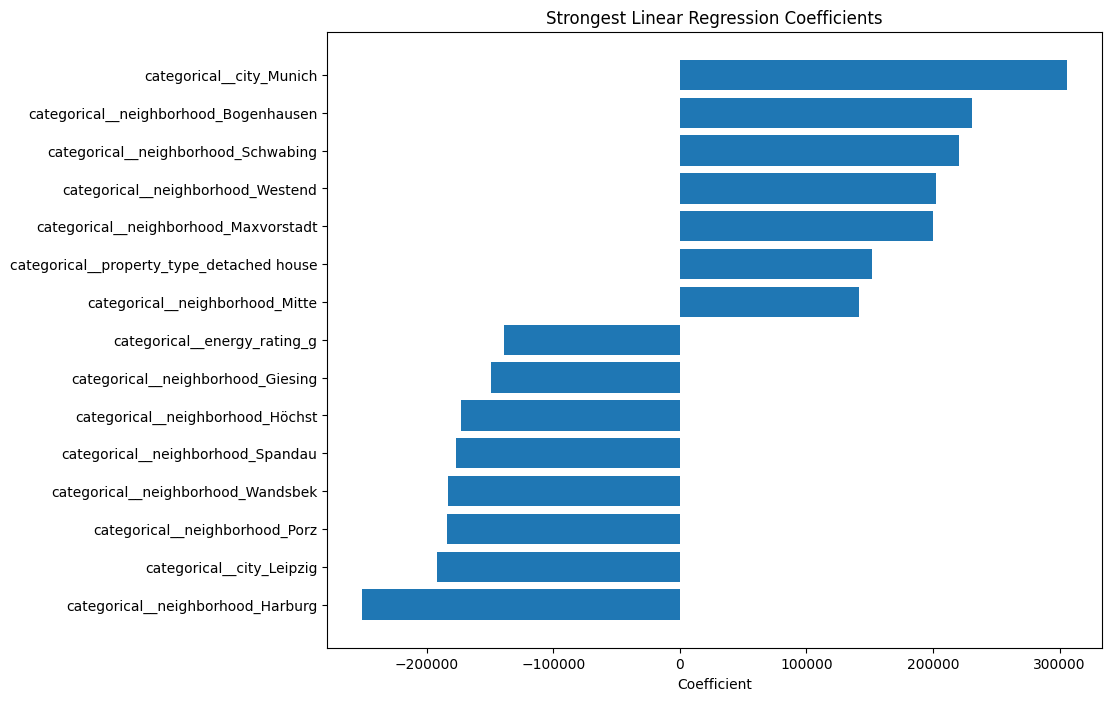

In [36]:
# ============================================================
# TOP LINEAR REGRESSION COEFFICIENTS
# ============================================================

top_coefficients = (
    coefficient_table
    .head(15)
    .sort_values("Coefficient")
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_coefficients["Feature"],
    top_coefficients["Coefficient"]
)

plt.title("Strongest Linear Regression Coefficients")
plt.xlabel("Coefficient")

plt.show()

In [37]:
# ============================================================
# PART B - LOGISTIC REGRESSION
# DEFINING THE TARGET
# ============================================================

# The assignment defines:
#
# high_price = 1 if sale_price_eur >= €500,000
# high_price = 0 otherwise

y_logistic = df["high_price"]

print("Target distribution:")
display(
    y_logistic.value_counts()
    .sort_index()
)

Target distribution:


,count
high_price,
0,439
1,761


In [38]:
# ============================================================
# TARGET PROPORTIONS
# ============================================================

target_proportions = (
    y_logistic
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(
    target_proportions.round(2)
)

high_price
0    36.58
1    63.42
Name: proportion, dtype: float64


In [39]:
# ============================================================
# DEFINING LOGISTIC REGRESSION FEATURES
# ============================================================

# IMPORTANT:
#
# sale_price_eur must not be included.
#
# high_price is the target.
#
# high_price_created is also derived from sale_price
# and therefore must not be included.
#
# house_id is an identifier and is not useful as a predictor.

X_logistic = df.drop(
    columns=[
        "house_id",
        "sale_price_eur",
        "high_price",
        "high_price_created"
    ]
)

print("Features used for logistic regression:")
print(X_logistic.columns.tolist())

Features used for logistic regression:
['city', 'neighborhood', 'property_type', 'bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'condition', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony', 'energy_rating']


In [40]:
# ============================================================
# LOGISTIC FEATURE TYPES
# ============================================================

logistic_numeric_features = (
    X_logistic
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

logistic_categorical_features = (
    X_logistic
    .select_dtypes(exclude=np.number)
    .columns
    .tolist()
)

print("Numerical features:")
print(logistic_numeric_features)

print("\nCategorical features:")
print(logistic_categorical_features)

Numerical features:
['bedrooms', 'bathrooms', 'living_area_sqm', 'lot_size_sqm', 'year_built', 'parking_spaces', 'distance_city_center_km', 'school_rating_1_10', 'crime_rate_1_10', 'has_garden', 'has_balcony']

Categorical features:
['city', 'neighborhood', 'property_type', 'condition', 'energy_rating']


In [41]:
# ============================================================
# LOGISTIC TRAIN/TEST SPLIT
# ============================================================

X_train_log, X_test_log, y_train_log, y_test_log = (
    train_test_split(
        X_logistic,
        y_logistic,
        test_size=0.20,
        random_state=42,
        stratify=y_logistic
    )
)

print("Training observations:", len(X_train_log))
print("Testing observations:", len(X_test_log))

Training observations: 960
Testing observations: 240


In [42]:
# ============================================================
# LOGISTIC PREPROCESSING
# ============================================================

# Numerical preprocessing:
#
# 1. Filling missing values using the median
# 2. Standardising numerical variables

logistic_numeric_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing:
#
# 1. Filling missing categories using the most-frequent category
# 2. One-hot encoding the categories

logistic_categorical_preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

preprocessor_logistic = ColumnTransformer(
    transformers=[
        (
            "numeric",
            logistic_numeric_preprocessor,
            logistic_numeric_features
        ),
        (
            "categorical",
            logistic_categorical_preprocessor,
            logistic_categorical_features
        )
    ]
)

print("Logistic preprocessing pipeline created")

Logistic preprocessing pipeline created


In [43]:
# ============================================================
# TRAINING LOGISTIC REGRESSION
# ============================================================

logistic_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor_logistic
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000
            )
        )
    ]
)

logistic_model.fit(
    X_train_log,
    y_train_log
)

print("Logistic regression model trained successfully")

Logistic regression model trained successfully


In [44]:
# ============================================================
# LOGISTIC PREDICTIONS
# ============================================================

logistic_predictions = (
    logistic_model.predict(X_test_log)
)

# Probability that each house belongs to class 1
logistic_probabilities = (
    logistic_model.predict_proba(X_test_log)[:, 1]
)

print("First 10 predicted classes:")
print(logistic_predictions[:10])

print("\nFirst 10 predicted probabilities:")
print(logistic_probabilities[:10])

First 10 predicted classes:
[0 1 0 0 0 1 0 0 1 0]

First 10 predicted probabilities:
[0.13344068 0.88695797 0.00263718 0.01369233 0.01635949 0.9312676
 0.00403121 0.36062895 0.99985085 0.00789069]


In [45]:
# ============================================================
# LOGISTIC REGRESSION METRICS
# ============================================================

accuracy = accuracy_score(
    y_test_log,
    logistic_predictions
)

precision = precision_score(
    y_test_log,
    logistic_predictions
)

recall = recall_score(
    y_test_log,
    logistic_predictions
)

f1 = f1_score(
    y_test_log,
    logistic_predictions
)

print("Logistic Regression Results")
print("=" * 40)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Logistic Regression Results
Accuracy : 0.9292
Precision: 0.9412
Recall   : 0.9474
F1 Score : 0.9443


Confusion Matrix:
[[ 79   9]
 [  8 144]]


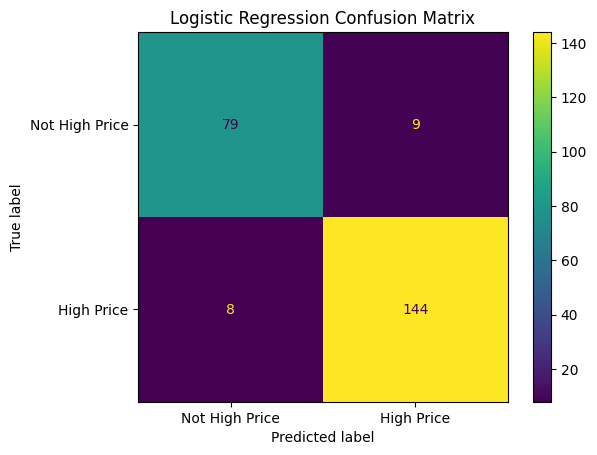

In [46]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test_log,
    logistic_predictions
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not High Price",
        "High Price"
    ]
)

disp.plot()

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [47]:
# ============================================================
# CONFUSION MATRIX COMPONENTS
# ============================================================

TN, FP, FN, TP = cm.ravel()

print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives :", TP)

# Manual calculations

manual_accuracy = (
    (TP + TN) /
    (TP + TN + FP + FN)
)

manual_precision = (
    TP /
    (TP + FP)
)

manual_recall = (
    TP /
    (TP + FN)
)

manual_f1 = (
    2 *
    manual_precision *
    manual_recall /
    (manual_precision + manual_recall)
)

print("\nManual metrics:")
print(f"Accuracy : {manual_accuracy:.4f}")
print(f"Precision: {manual_precision:.4f}")
print(f"Recall   : {manual_recall:.4f}")
print(f"F1       : {manual_f1:.4f}")

True Negatives : 79
False Positives: 9
False Negatives: 8
True Positives : 144

Manual metrics:
Accuracy : 0.9292
Precision: 0.9412
Recall   : 0.9474
F1       : 0.9443


In [48]:
# ============================================================
# LOGISTIC REGRESSION COEFFICIENTS
# ============================================================

fitted_log_preprocessor = (
    logistic_model
    .named_steps["preprocessing"]
)

logistic_feature_names = (
    fitted_log_preprocessor
    .get_feature_names_out()
)

logistic_coefficients = (
    logistic_model
    .named_steps["model"]
    .coef_[0]
)

logistic_coefficient_table = pd.DataFrame({
    "Feature": logistic_feature_names,
    "Coefficient": logistic_coefficients
})

logistic_coefficient_table["Absolute_Coefficient"] = (
    logistic_coefficient_table["Coefficient"].abs()
)

logistic_coefficient_table = (
    logistic_coefficient_table
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
)

display(
    logistic_coefficient_table.head(20)
)

,Feature,Coefficient,Absolute_Coefficient
2,numeric__living_area_sqm,2.891387,2.891387
15,categorical__city_Munich,2.801346,2.801346
14,categorical__city_Leipzig,-2.542448,2.542448
26,categorical__neighborhood_Grünau,-2.151055,2.151055
27,categorical__neighborhood_Harburg,-2.113309,2.113309
44,categorical__neighborhood_Spandau,-1.878275,1.878275
3,numeric__lot_size_sqm,1.650660,1.650660
48,categorical__neighborhood_Westend,1.627049,1.627049
28,categorical__neighborhood_Höchst,-1.605896,1.605896
47,categorical__neighborhood_Wandsbek,-1.513717,1.513717


In [49]:
# ============================================================
# LOGISTIC ODDS RATIOS
# ============================================================

odds_ratio_table = logistic_coefficient_table.copy()

odds_ratio_table["Odds_Ratio"] = np.exp(
    odds_ratio_table["Coefficient"]
)

display(
    odds_ratio_table.head(20)
)

,Feature,Coefficient,Absolute_Coefficient,Odds_Ratio
2,numeric__living_area_sqm,2.891387,2.891387,18.018276
15,categorical__city_Munich,2.801346,2.801346,16.466793
14,categorical__city_Leipzig,-2.542448,2.542448,0.078674
26,categorical__neighborhood_Grünau,-2.151055,2.151055,0.116361
27,categorical__neighborhood_Harburg,-2.113309,2.113309,0.120838
44,categorical__neighborhood_Spandau,-1.878275,1.878275,0.152853
3,numeric__lot_size_sqm,1.650660,1.650660,5.210416
48,categorical__neighborhood_Westend,1.627049,1.627049,5.088835
28,categorical__neighborhood_Höchst,-1.605896,1.605896,0.200710
47,categorical__neighborhood_Wandsbek,-1.513717,1.513717,0.220090


In [50]:
# ============================================================
# FINAL RESULTS SUMMARY
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression"
    ],

    "Metric 1": [
        f"MAE = €{mae:,.0f}",
        f"Accuracy = {accuracy:.4f}"
    ],

    "Metric 2": [
        f"RMSE = €{rmse:,.0f}",
        f"Precision = {precision:.4f}"
    ],

    "Metric 3": [
        f"R² = {r2:.4f}",
        f"Recall = {recall:.4f}"
    ],

    "Metric 4": [
        "",
        f"F1 = {f1:.4f}"
    ]
})

display(results)

,Model,Metric 1,Metric 2,Metric 3,Metric 4
0,Linear Regression,"MAE = €100,874","RMSE = €140,585",R² = 0.8796,
1,Logistic Regression,Accuracy = 0.9292,Precision = 0.9412,Recall = 0.9474,F1 = 0.9443


In [51]:
# ------------------------------------------------------------
# FINAL FORMATTING FOR THE CLEANED DATASET
# ------------------------------------------------------------

# Renaming column titles first to standardise names
# Added errors='ignore' to prevent KeyError if source column doesn't exist
# in case of partial runs or already renamed columns
df = df.rename(columns={
    "house_id": "House_ID",
    "city": "City",
    "neighborhood": "Neighborhood",
    "property_type": "Property_type",
    "bedrooms": "Bedrooms",
    "bathrooms": "Bathrooms",
    "living_area_sqm": "Living_area_sqm",
    "lot_size_sqm": "Lot_size_sqm",
    "year_built": "Year_built",
    "condition": "Condition",
    "parking_spaces": "Parking_spaces",
    "distance_city_center_km": "Distance_city_center_km",
    "school_rating_1_10": "School_rating_1_10",
    "crime_rate_1_10": "Crime_rate_1_10",
    "has_garden": "Has_garden?",
    "has_balcony": "Has_balcony?",
    "energy_rating": "Energy_rating",
    "sale_price_eur": "Sale_price_eur",
    "high_price": "High_price?"
}, errors='ignore')

# Capitalising values for appropriate categorical columns
# 'City' and 'Neighborhood' values already title-cased
# Title-casing 'Property_type' and 'Condition'
for column in ["Property_type", "Condition"]:
    # Ensuring column exists and is of object/string type before applying str.title()
    if column in df.columns and pd.api.types.is_object_dtype(df[column]):
        df[column] = df[column].str.title()

# Energy ratings in capital letters for their values
if "Energy_rating" in df.columns and pd.api.types.is_object_dtype(df["Energy_rating"]):
    df["Energy_rating"] = df["Energy_rating"].str.upper()

# Converting Boolean-like columns from 0/1 to Yes/No strings
boolean_display_map = {1: "Yes", 0: "No"}
for column_name in ["Has_garden?", "Has_balcony?", "High_price?"]:
    if column_name in df.columns and pd.api.types.is_integer_dtype(df[column_name]):
        df[column_name] = df[column_name].map(boolean_display_map)

# Removing the temporary verification column
df = df.drop(columns=["high_price_created"], errors="ignore")

print("Final formatting completed")
display(df.head())

Final formatting completed


,House_ID,City,Neighborhood,Property_type,Bedrooms,Bathrooms,Living_area_sqm,Lot_size_sqm,Year_built,Condition,Parking_spaces,Distance_city_center_km,School_rating_1_10,Crime_rate_1_10,Has_garden?,Has_balcony?,Energy_rating,Sale_price_eur,High_price?
0,H0001,Frankfurt,Westend,Apartment,3.0,1.0,79.2,0.0,2004.0,Excellent,1,1.5,6.6,2.6,No,No,D,675000,Yes
1,H0002,Frankfurt,Gallus,Terraced House,5.0,2.0,127.3,514.9,1979.0,Average,2,4.1,7.4,3.6,No,Yes,D,716000,Yes
2,H0003,Frankfurt,Bockenheim,Apartment,2.0,1.0,45.8,0.0,2004.0,Needs Renovation,0,4.2,8.7,4.3,No,Yes,A+,266000,No
3,H0004,Hamburg,Harburg,Terraced House,5.0,2.0,182.5,529.9,2019.0,Needs Renovation,2,20.2,8.9,4.2,Yes,Yes,C,622000,Yes
4,H0005,Cologne,Sülz,Detached House,3.0,1.0,98.1,507.0,1979.0,Good,1,0.4,7.5,4.2,Yes,Yes,B,780000,Yes


In [52]:
# ============================================================
# SAVING the CLEANED DATASET
# ============================================================

output_path = (
    "/content/drive/MyDrive/ML_assignments_with_Abdul/"
    "house_pricing_cleaned.csv"
)

df.to_csv(
    output_path,
    index=False
)

print("Cleaned dataset saved to:")
print(output_path)


Cleaned dataset saved to:
/content/drive/MyDrive/ML_assignments_with_Abdul/house_pricing_cleaned.csv


In [53]:
# ============================================================
# (OPTIONAL) -- SEARCHING GOOGLE DRIVE FOR THE CSV
# ============================================================

import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

/content/drive/MyDrive/ML_assignments_with_Abdul/house_pricing_ml_exercise.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/house_pricing_cleaned.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_2/house_pricing_ml_exercise.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_1/model_results.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_1/house_pricing_cleaned.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_1/house_pricing_ml_exercise.csv
/content/drive/MyDrive/ML_assignments_with_Abdul/Week_3/house_pricing_ml_exercise.csv
